In [ ]:
from google.colab import files
uploaded = files.upload()

Saving SampleSuperstore.csv to SampleSuperstore.csv


In [ ]:
import pandas as pd

df = pd.read_csv("SampleSuperstore.csv")
df.head()

,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit
0,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,261.9600,2,0.00,41.9136
1,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,731.9400,3,0.00,219.5820
2,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,14.6200,2,0.00,6.8714
3,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,957.5775,5,0.45,-383.0310
4,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,22.3680,2,0.20,2.5164


In [ ]:

# Step 1: Inspect our retail dataset

print("Dataset size (rows, columns):", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values in each column:")
display(df.isnull().sum())

print("\nColumn data types:")
display(df.dtypes)


Dataset size (rows, columns): (9994, 13)

Column names:
['Ship Mode', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Category', 'Sub-Category', 'Sales', 'Quantity', 'Discount', 'Profit']

First 5 rows:


,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit
0,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,261.9600,2,0.00,41.9136
1,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,731.9400,3,0.00,219.5820
2,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,14.6200,2,0.00,6.8714
3,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,957.5775,5,0.45,-383.0310
4,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,22.3680,2,0.20,2.5164



Missing values in each column:


,0
Ship Mode,0
Segment,0
Country,0
City,0
State,0
Postal Code,0
Region,0
Category,0
Sub-Category,0
Sales,0



Column data types:


,0
Ship Mode,object
Segment,object
Country,object
City,object
State,object
Postal Code,int64
Region,object
Category,object
Sub-Category,object
Sales,float64


In [ ]:

# Step 2: Calculate key business metrics

print("Total Sales:", round(df["Sales"].sum(), 2))

if "Profit" in df.columns:
    print("Total Profit:", round(df["Profit"].sum(), 2))

if "Order ID" in df.columns:
    print("Total Orders:", df["Order ID"].nunique())

if "Quantity" in df.columns:
    print("Total Items Sold:", df["Quantity"].sum())


Total Sales: 2297200.86
Total Profit: 286397.02
Total Items Sold: 37873


In [ ]:

# Step 3: Compare sales and profit by category

if {"Category", "Sales", "Profit"}.issubset(df.columns):
    category_report = (
        df.groupby("Category")
          .agg(
              Total_Sales=("Sales", "sum"),
              Total_Profit=("Profit", "sum")
          )
          .sort_values("Total_Profit", ascending=False)
          .round(2)
    )

    display(category_report)
else:
    print("Some expected columns are missing.")
    print(df.columns.tolist())


,Total_Sales,Total_Profit
Category,,
Technology,836154.03,145454.95
Office Supplies,719047.03,122490.80
Furniture,741999.80,18451.27


In [ ]:

# Step 4: Analyze profit by product sub-category

report = (
    df.groupby("Sub-Category")
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Profit", "sum"),
          Units_Sold=("Quantity", "sum")
      )
)

report["Profit_Margin_%"] = (
    report["Total_Profit"] / report["Total_Sales"] * 100
).round(2)

report = report.sort_values("Total_Profit")

display(report.round(2))


,Total_Sales,Total_Profit,Units_Sold,Profit_Margin_%
Sub-Category,,,,
Tables,206965.53,-17725.48,1241,-8.56
Bookcases,114880.00,-3472.56,868,-3.02
Supplies,46673.54,-1189.10,647,-2.55
Fasteners,3024.28,949.52,914,31.40
Machines,189238.63,3384.76,440,1.79
Labels,12486.31,5546.25,1400,44.42
Art,27118.79,6527.79,3000,24.07
Envelopes,16476.40,6964.18,906,42.27
Furnishings,91705.16,13059.14,3563,14.24


In [ ]:

# Step 5: Analyze profit at different discount levels

discount_report = (
    df.groupby("Discount")
      .agg(
          Number_of_Records=("Sales", "size"),
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Profit", "sum")
      )
)

discount_report["Profit_Margin_%"] = (
    discount_report["Total_Profit"]
    / discount_report["Total_Sales"] * 100
).round(2)

display(discount_report.round(2))


,Number_of_Records,Total_Sales,Total_Profit,Profit_Margin_%
Discount,,,,
0.00,4798,1087908.47,320987.60,29.51
0.10,94,54369.35,9029.18,16.61
0.15,52,27558.52,1418.99,5.15
0.20,3657,764594.37,90337.31,11.82
0.30,227,103226.66,-10369.28,-10.05
0.32,27,14493.46,-2391.14,-16.50
0.40,206,116417.78,-23057.05,-19.81
0.45,11,5484.97,-2493.11,-45.45
0.50,66,58918.54,-20506.43,-34.80


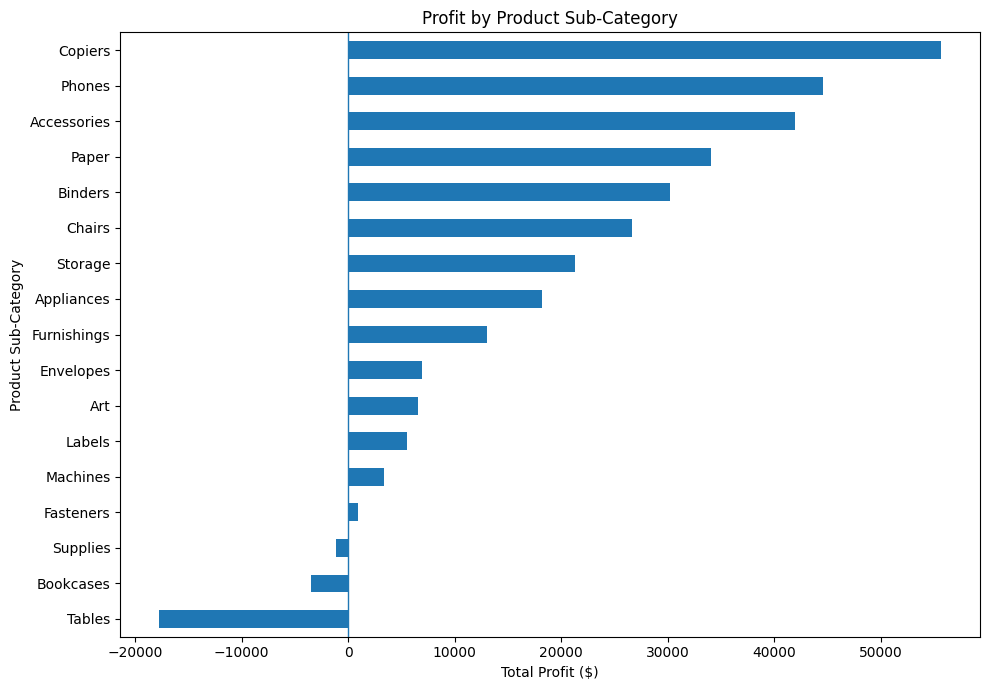

In [ ]:

import matplotlib.pyplot as plt

# Sort products from highest to lowest profit
profit_by_product = (
    df.groupby("Sub-Category")["Profit"]
      .sum()
      .sort_values()
)

# Create a chart
plt.figure(figsize=(10, 7))
profit_by_product.plot(kind="barh")

plt.title("Profit by Product Sub-Category")
plt.xlabel("Total Profit ($)")
plt.ylabel("Product Sub-Category")
plt.axvline(x=0, linewidth=1)
plt.tight_layout()
plt.show()


In [ ]:

# Compare product profitability at each discount level

discount_product_report = (
    df.groupby(["Sub-Category", "Discount"])
      .agg(
          Records=("Sales", "size"),
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum")
      )
      .reset_index()
)

# Keep only combinations that made a loss
loss_report = (
    discount_product_report[
        discount_product_report["Profit"] < 0
    ]
    .sort_values("Profit")
)

display(loss_report.head(15).round(2))


,Sub-Category,Discount,Records,Sales,Profit
11,Binders,0.8,233,13581.22,-21909.40
41,Machines,0.7,23,15601.51,-19579.32
10,Binders,0.7,380,22559.39,-16601.10
54,Tables,0.4,75,45614.41,-16187.40
5,Appliances,0.8,67,3382.53,-8629.64
56,Tables,0.5,36,13675.01,-8615.39
40,Machines,0.5,12,37935.07,-7635.23
22,Chairs,0.3,158,70005.50,-6737.12
46,Phones,0.4,109,34337.35,-6385.79
32,Furnishings,0.6,138,6644.70,-5944.66


In [ ]:

!pip -q install plotly

import plotly.express as px

# Prepare category-level data
category_data = (
    df.groupby("Category", as_index=False)
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Quantity=("Quantity", "sum")
      )
)

# Chart 1: Sales by category
fig1 = px.bar(
    category_data,
    x="Category",
    y="Sales",
    title="Total Sales by Category",
    text_auto=".3s"
)
fig1.show()

# Chart 2: Profit by category
fig2 = px.bar(
    category_data,
    x="Category",
    y="Profit",
    title="Total Profit by Category",
    text_auto=".3s"
)
fig2.show()


In [ ]:

from pathlib import Path

# Create a folder for portfolio files
project = Path("retail_sales_portfolio")
project.mkdir(exist_ok=True)

# Save interactive charts
fig1.write_html(project / "sales_by_category.html")
fig2.write_html(project / "profit_by_category.html")

# Create the project README
readme = """
# Retail Sales and Profitability Analysis

## Business Problem
Understand retail sales performance, identify profitable
product categories, and investigate product losses and discounts.

## Tools Used
- Python
- Pandas
- Plotly
- Google Colab

## Dataset
Sample Superstore retail dataset containing 9,994 records
and 13 columns.

## Key Findings
- Total sales: $2,297,200.86
- Total profit: $286,397.02
- Overall profit margin: 12.47%
- Items sold: 37,873
- Tables, Bookcases, and Supplies had combined losses
  of $22,387.14.
- Copiers generated $55,617.82 in profit.
- Discount levels of 30% and above showed losses in
  the aggregate results for this dataset.

## Recommendations
1. Investigate pricing and costs for loss-making products.
2. Review high-discount transactions.
3. Evaluate opportunities to grow profitable product lines.
4. Monitor sales, profit, and profit margin regularly.

## Limitations
The dataset used in this analysis does not contain order
dates, order IDs, or customer IDs. Time trends, unique order
counts, and customer-level analysis are therefore excluded.

The findings describe this sample dataset and should not
be treated as proof of cause and effect.

## Next Steps
Develop an interactive business dashboard and validate
recommendations through further product-level analysis.
"""

(project / "README.md").write_text(readme.strip(), encoding="utf-8")

print("Project files created:")
for file in project.iterdir():
    print(file.name)


Project files created:
README.md
profit_by_category.html
sales_by_category.html


In [ ]:

import shutil
from google.colab import files

shutil.make_archive(
    "retail_sales_portfolio",
    "zip",
    "retail_sales_portfolio"
)

files.download("retail_sales_portfolio.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# STEP 1: Investigate loss-making product sub-categories

# Group sales data by product sub-category
subcategory_analysis = (
    df.groupby("Sub-Category")
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Profit", "sum"),
          Units_Sold=("Quantity", "sum"),
          Average_Discount=("Discount", "mean"),
          Number_of_Orders=("Profit", "count")
      )
      .reset_index()
)

# Calculate profit margin as a percentage
subcategory_analysis["Profit_Margin_%"] = (
    subcategory_analysis["Total_Profit"]
    / subcategory_analysis["Total_Sales"] * 100
)

# Show the biggest losses first
loss_making_products = (
    subcategory_analysis[
        subcategory_analysis["Total_Profit"] < 0
    ]
    .sort_values("Total_Profit", ascending=True)
)

# Display the results
print("LOSS-MAKING PRODUCT SUB-CATEGORIES")
display(loss_making_products.round(2))


LOSS-MAKING PRODUCT SUB-CATEGORIES


,Sub-Category,Total_Sales,Total_Profit,Units_Sold,Average_Discount,Number_of_Orders,Profit_Margin_%
16,Tables,206965.53,-17725.48,1241,0.26,319,-8.56
4,Bookcases,114880.00,-3472.56,868,0.21,228,-3.02
15,Supplies,46673.54,-1189.10,647,0.08,190,-2.55


In [ ]:
import pandas as pd
import os

# Find CSV files in the Colab folder
print(os.listdir('/content'))

['.config', 'SampleSuperstore.csv', 'sample_data']


In [ ]:
import pandas as pd

df = pd.read_csv('/content/SampleSuperstore.csv')

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

display(df.head())

Dataset loaded successfully!
Number of rows and columns: (9994, 13)


,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit
0,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,261.9600,2,0.00,41.9136
1,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,731.9400,3,0.00,219.5820
2,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,14.6200,2,0.00,6.8714
3,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,957.5775,5,0.45,-383.0310
4,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,22.3680,2,0.20,2.5164


In [ ]:

# STEP 2: Analyze losses by product sub-category and discount

loss_analysis = (
    df[df["Sub-Category"].isin(["Tables", "Bookcases", "Supplies"])]
    .groupby(["Sub-Category", "Discount"])
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Number_of_Orders=("Profit", "count")
    )
    .reset_index()
)

loss_analysis["Profit_Margin_%"] = (
    loss_analysis["Total_Profit"] / loss_analysis["Total_Sales"] * 100
)

display(
    loss_analysis
    .sort_values(["Sub-Category", "Discount"])
    .round(2)
)


,Sub-Category,Discount,Total_Sales,Total_Profit,Number_of_Orders,Profit_Margin_%
0,Bookcases,0.00,31935.98,6075.71,60,19.02
1,Bookcases,0.15,27558.52,1418.99,52,5.15
2,Bookcases,0.20,26841.50,130.50,46,0.49
3,Bookcases,0.30,4282.70,-555.87,10,-12.98
4,Bookcases,0.32,14493.46,-2391.14,27,-16.50
5,Bookcases,0.50,7308.46,-4255.81,18,-58.23
6,Bookcases,0.70,2459.38,-3894.94,15,-158.37
7,Supplies,0.00,31559.21,1718.39,117,5.44
8,Supplies,0.20,15114.33,-2907.49,73,-19.24
9,Tables,0.00,71578.76,13276.30,72,18.55


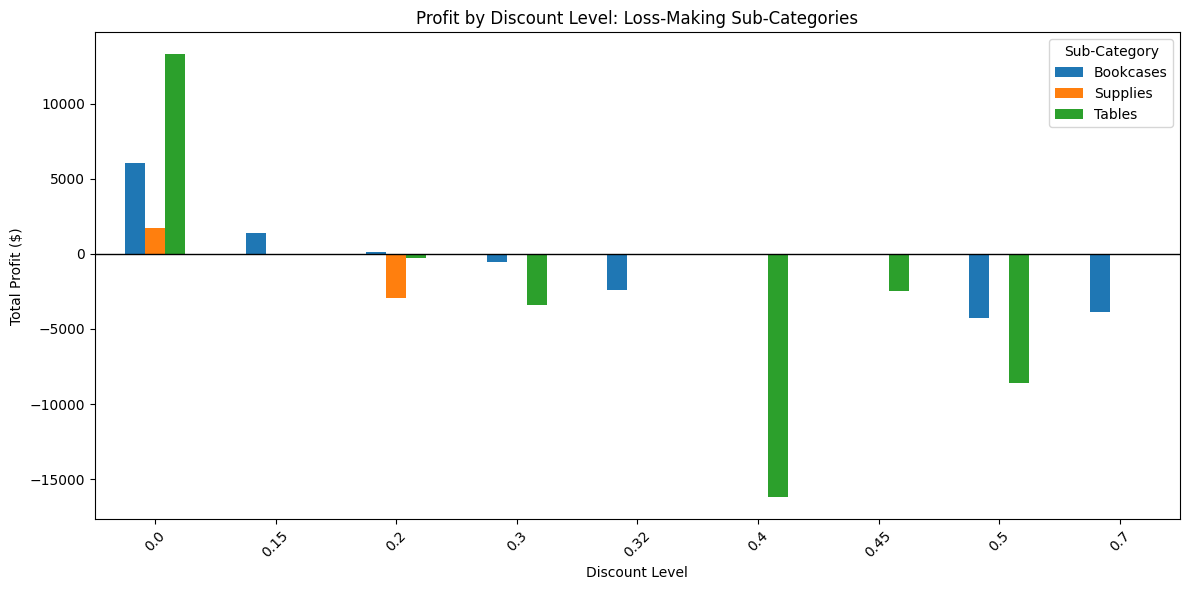

In [ ]:

import matplotlib.pyplot as plt
import pandas as pd

# Prepare the data for the chart
profit_pivot = loss_analysis.pivot(
    index="Discount",
    columns="Sub-Category",
    values="Total_Profit"
)

# Plot profit by discount level
profit_pivot.plot(kind="bar", figsize=(12, 6))

plt.axhline(y=0, color="black", linewidth=1)
plt.title("Profit by Discount Level: Loss-Making Sub-Categories")
plt.xlabel("Discount Level")
plt.ylabel("Total Profit ($)")
plt.xticks(rotation=45)
plt.legend(title="Sub-Category")
plt.tight_layout()
plt.show()


In [ ]:

# STEP 4: Find the biggest losses by individual product

product_loss_analysis = (
    df.groupby(["Sub-Category", "Product Name"])
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Profit", "sum"),
          Units_Sold=("Quantity", "sum"),
          Average_Discount=("Discount", "mean"),
          Number_of_Orders=("Profit", "count")
      )
      .reset_index()
)

# Keep products with an overall loss
loss_making_products = (
    product_loss_analysis[
        product_loss_analysis["Total_Profit"] < 0
    ]
    .sort_values("Total_Profit", ascending=True)
)

# Show the 10 products with the largest total losses
print("TOP 10 LOSS-MAKING PRODUCTS")
display(loss_making_products.head(10).round(2))


KeyError: 'Product Name'

In [ ]:

print(df.columns.tolist())


['Ship Mode', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Category', 'Sub-Category', 'Sales', 'Quantity', 'Discount', 'Profit']


In [ ]:

# STEP 5: Analyze loss-making sub-categories by region

regional_loss_analysis = (
    df[df["Sub-Category"].isin(["Tables", "Bookcases", "Supplies"])]
    .groupby(["Region", "Sub-Category"])
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Units_Sold=("Quantity", "sum"),
        Number_of_Orders=("Profit", "count")
    )
    .reset_index()
)

regional_loss_analysis["Profit_Margin_%"] = (
    regional_loss_analysis["Total_Profit"]
    / regional_loss_analysis["Total_Sales"] * 100
)

display(
    regional_loss_analysis
    .sort_values("Total_Profit")
    .round(2)
)


,Region,Sub-Category,Total_Sales,Total_Profit,Units_Sold,Number_of_Orders,Profit_Margin_%
5,East,Tables,39139.81,-11025.38,271,80,-28.17
8,South,Tables,43916.19,-4623.06,227,51,-10.53
2,Central,Tables,39154.97,-3559.65,262,72,-9.09
0,Central,Bookcases,24157.18,-1997.90,192,50,-8.27
9,West,Bookcases,36004.12,-1646.51,306,80,-4.57
3,East,Bookcases,43819.33,-1167.63,252,70,-2.66
4,East,Supplies,10760.12,-1155.14,195,56,-10.74
1,Central,Supplies,9467.37,-661.89,122,36,-6.99
7,South,Supplies,8318.93,1.88,92,29,0.02
10,West,Supplies,18127.12,626.05,238,69,3.45


In [ ]:

# STEP 6: Calculate combined profit by region

regional_summary = (
    df[df["Sub-Category"].isin(["Tables", "Bookcases", "Supplies"])]
    .groupby("Region")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Units_Sold=("Quantity", "sum"),
        Number_of_Orders=("Profit", "count")
    )
    .reset_index()
)

regional_summary["Profit_Margin_%"] = (
    regional_summary["Total_Profit"]
    / regional_summary["Total_Sales"] * 100
)

regional_summary = regional_summary.sort_values(
    "Total_Profit", ascending=True
)

display(regional_summary.round(2))


,Region,Total_Sales,Total_Profit,Units_Sold,Number_of_Orders,Profit_Margin_%
1,East,93719.26,-13348.15,718,206,-14.24
0,Central,72779.52,-6219.44,576,158,-8.55
2,South,63134.48,-3281.69,437,108,-5.20
3,West,138885.81,462.14,1025,265,0.33


In [ ]:

# STEP 7: Analyze regional profit by discount level

regional_discount_analysis = (
    df[df["Sub-Category"].isin(["Tables", "Bookcases", "Supplies"])]
    .groupby(["Region", "Discount"])
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Number_of_Orders=("Profit", "count")
    )
    .reset_index()
)

regional_discount_analysis["Profit_Margin_%"] = (
    regional_discount_analysis["Total_Profit"]
    / regional_discount_analysis["Total_Sales"] * 100
)

display(
    regional_discount_analysis
    .sort_values(["Region", "Discount"])
    .round(2)
)


,Region,Discount,Total_Sales,Total_Profit,Number_of_Orders,Profit_Margin_%
0,Central,0.00,26997.12,4077.84,44,15.10
1,Central,0.20,4694.91,-823.85,26,-17.55
2,Central,0.30,20043.36,-2772.55,43,-13.83
3,Central,0.32,14493.46,-2391.14,27,-16.50
4,Central,0.50,6550.67,-4309.74,18,-65.79
5,East,0.00,17304.83,3124.64,57,18.06
6,East,0.20,29966.16,-1191.59,51,-3.98
7,East,0.30,9421.49,-1185.65,21,-12.58
8,East,0.40,29718.32,-9839.73,59,-33.11
9,East,0.50,7308.46,-4255.81,18,-58.23


In [ ]:

# STEP 8: Rank the biggest losses by region, sub-category, and discount

priority_analysis = (
    df[df["Sub-Category"].isin(["Tables", "Bookcases", "Supplies"])]
    .groupby(["Region", "Sub-Category", "Discount"])
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Number_of_Orders=("Profit", "count")
    )
    .reset_index()
)

priority_analysis["Profit_Margin_%"] = (
    priority_analysis["Total_Profit"]
    / priority_analysis["Total_Sales"] * 100
)

top_losses = (
    priority_analysis[priority_analysis["Total_Profit"] < 0]
    .sort_values("Total_Profit")
    .head(10)
)

display(top_losses.round(2))


,Region,Sub-Category,Discount,Total_Sales,Total_Profit,Number_of_Orders,Profit_Margin_%
14,East,Tables,0.40,29718.32,-9839.73,59,-33.11
20,South,Tables,0.40,15896.09,-6347.67,16,-39.93
7,Central,Tables,0.50,6550.67,-4309.74,18,-65.79
29,West,Tables,0.50,7124.34,-4305.64,18,-60.44
10,East,Bookcases,0.50,7308.46,-4255.81,18,-58.23
24,West,Bookcases,0.70,2459.38,-3894.94,15,-158.37
21,South,Tables,0.45,5484.97,-2493.11,11,-45.45
2,Central,Bookcases,0.32,14493.46,-2391.14,27,-16.50
6,Central,Tables,0.30,15760.66,-2216.68,33,-14.06
12,East,Supplies,0.20,7189.02,-1542.47,19,-21.46


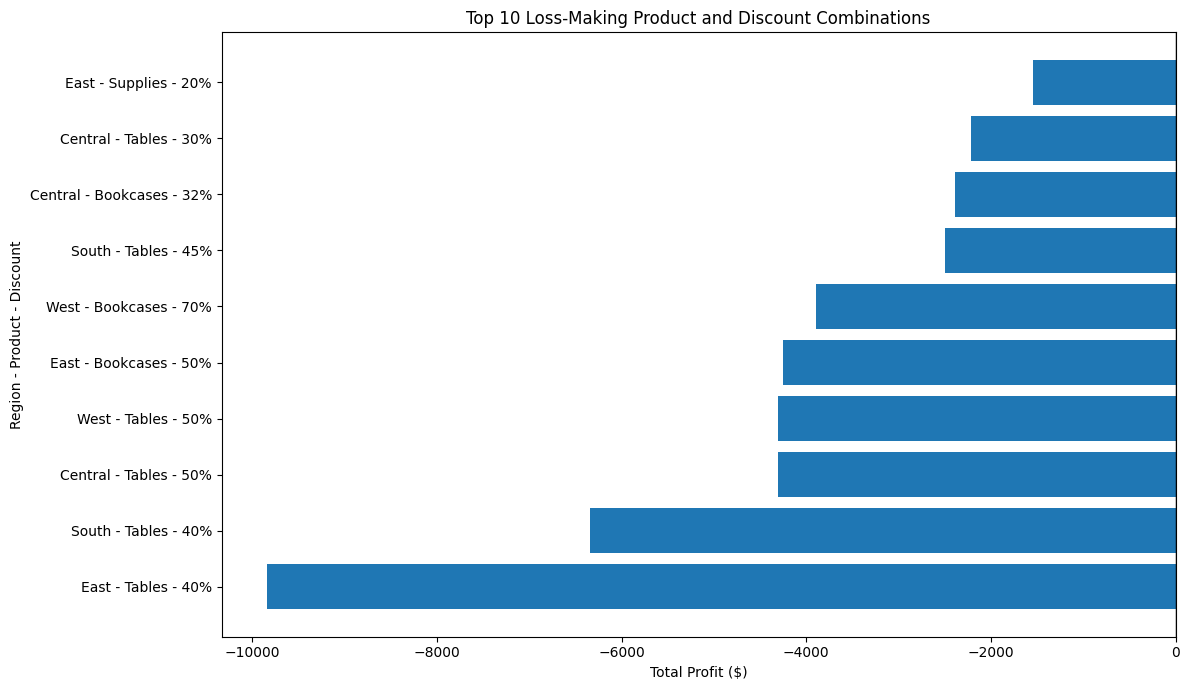

In [ ]:

import matplotlib.pyplot as plt

# Create labels for each region, product, and discount
chart_data = top_losses.copy()

chart_data["Label"] = (
    chart_data["Region"] + " - " +
    chart_data["Sub-Category"] + " - " +
    (chart_data["Discount"] * 100).round(0).astype(int).astype(str) + "%"
)

chart_data = chart_data.sort_values("Total_Profit")

plt.figure(figsize=(12, 7))
plt.barh(chart_data["Label"], chart_data["Total_Profit"])
plt.axvline(x=0, color="black", linewidth=1)
plt.title("Top 10 Loss-Making Product and Discount Combinations")
plt.xlabel("Total Profit ($)")
plt.ylabel("Region - Product - Discount")
plt.tight_layout()
plt.show()


In [ ]:
plt.savefig("top_10_loss_making_combinations.png",
            dpi=300, bbox_inches="tight")
print("Chart saved successfully!")

Chart saved successfully!


<Figure size 640x480 with 0 Axes>

In [ ]:
from google.colab import files

files.download("top_10_loss_making_combinations.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
business_recommendations = [
    {
        "Problem": "Tables are losing money",
        "Evidence": "Tables lost $17,725.48 overall.",
        "Recommendation": "Review pricing, product costs, and discount levels."
    },
    {
        "Problem": "High discounts are associated with losses",
        "Evidence": "Tables lost $9,839.73 in the East at a 40% discount.",
        "Recommendation": "Review large discounts, especially on Tables, before approving them."
    },
    {
        "Problem": "Bookcases are unprofitable in some regions",
        "Evidence": "Bookcases lost $4,255.81 in the East at a 50% discount.",
        "Recommendation": "Evaluate Bookcase pricing and discount policies."
    },
    {
        "Problem": "Regional performance differs",
        "Evidence": "The selected loss-making subcategories lost $13,348.15 in the East.",
        "Recommendation": "Investigate regional costs, pricing, and discount practices."
    }
]

recommendations_df = pd.DataFrame(business_recommendations)

display(recommendations_df)

,Problem,Evidence,Recommendation
0,Tables are losing money,"Tables lost $17,725.48 overall.","Review pricing, product costs, and discount le..."
1,High discounts are associated with losses,"Tables lost $9,839.73 in the East at a 40% dis...","Review large discounts, especially on Tables, ..."
2,Bookcases are unprofitable in some regions,"Bookcases lost $4,255.81 in the East at a 50% ...",Evaluate Bookcase pricing and discount policies.
3,Regional performance differs,The selected loss-making subcategories lost $1...,"Investigate regional costs, pricing, and disco..."


In [ ]:
recommendations_df.to_csv(
    "business_recommendations.csv",
    index=False
)

from google.colab import files
files.download("business_recommendations.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

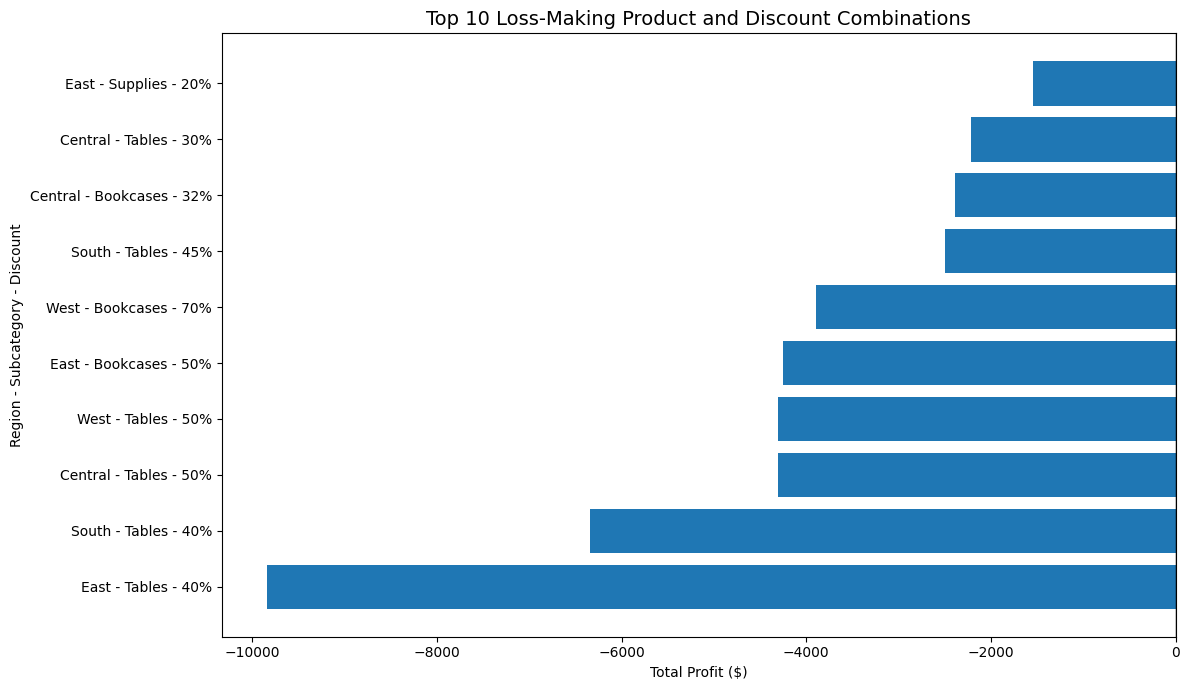

Chart recreated and saved successfully!


In [ ]:

import matplotlib.pyplot as plt

# Recreate the chart from your existing top_losses table
chart_data = top_losses.copy()

chart_data["Label"] = (
    chart_data["Region"] + " - " +
    chart_data["Sub-Category"] + " - " +
    (chart_data["Discount"] * 100)
    .round(0).astype(int).astype(str) + "%"
)

chart_data = chart_data.sort_values("Total_Profit")

fig, ax = plt.subplots(figsize=(12, 7))

ax.barh(chart_data["Label"], chart_data["Total_Profit"])
ax.axvline(x=0, color="black", linewidth=1)

ax.set_title(
    "Top 10 Loss-Making Product and Discount Combinations",
    fontsize=14
)
ax.set_xlabel("Total Profit ($)")
ax.set_ylabel("Region - Subcategory - Discount")

fig.tight_layout()

# Save BEFORE displaying the chart
fig.savefig(
    "top_10_loss_making_combinations.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Chart recreated and saved successfully!")


In [ ]:

import pandas as pd
from google.colab import files

recommendations = pd.DataFrame({
    "Business Problem": [
        "Tables are losing money",
        "High discounts are linked to losses",
        "Bookcases are losing money",
        "The East region has the largest combined loss"
    ],
    "Key Finding": [
        "Tables lost $17,725.48 overall.",
        "Tables lost $9,839.73 in the East at a 40% discount.",
        "Bookcases lost $4,255.81 in the East at a 50% discount.",
        "Tables, Bookcases, and Supplies lost $13,348.15 combined."
    ],
    "Recommended Action": [
        "Review Tables pricing, costs, and discount policies.",
        "Review high-discount orders before approving them.",
        "Check Bookcases costs and pricing in the East.",
        "Investigate regional pricing, costs, and discount practices."
    ]
})

# Save as a readable Excel spreadsheet
file_name = "Business_Recommendations.xlsx"

with pd.ExcelWriter(file_name, engine="openpyxl") as writer:
    recommendations.to_excel(
        writer, index=False, sheet_name="Recommendations"
    )
    worksheet = writer.sheets["Recommendations"]
    worksheet.freeze_panes = "A2"
    worksheet.column_dimensions["A"].width = 32
    worksheet.column_dimensions["B"].width = 55
    worksheet.column_dimensions["C"].width = 55

    for row in worksheet.iter_rows():
        for cell in row:
            cell.alignment = cell.alignment.copy(
                wrap_text=True, vertical="top"
            )

    for cell in worksheet[1]:
        cell.font = cell.font.copy(bold=True)

    for row_num in range(2, worksheet.max_row + 1):
        worksheet.row_dimensions[row_num].height = 45

files.download(file_name)


/tmp/ipykernel_1861/2661282722.py:40: DeprecationWarning: Call to deprecated function copy (Use copy(obj) or cell.obj = cell.obj + other).
  cell.alignment = cell.alignment.copy(
/tmp/ipykernel_1861/2661282722.py:45: DeprecationWarning: Call to deprecated function copy (Use copy(obj) or cell.obj = cell.obj + other).
  cell.font = cell.font.copy(bold=True)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>